# Sélection prédictive des magasins Franprix

Ce notebook construit un modèle de régression linéaire pour prédire le **CA moyen stabilisé d’un corner**.

- Cible : CA hebdomadaire moyen stabilisé, en euros
- Variable du modèle final : Nombre de tickets
- Validation : Leave-One-Out
- Seuils métier : 850 € (CA cible) et 700 € (CA minimum accepté)



In [1]:
# Imports
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    import statsmodels.api as sm
    statsmodels_disponible = True
except ImportError:
    statsmodels_disponible = False

print("Bibliothèques importées avec succès")

Bibliothèques importées avec succès


In [2]:
#Chargement de la base
df_brut = pd.read_excel("Dashboard Krispy kreme  VDFF 1.xlsx")

# Copie de travail pour ne jamais modifier la base brute
df_clean = df_brut.copy()

# Nettoyage des noms de colonnes
df_clean.columns = (
    df_clean.columns
    .astype(str)
    .str.replace("\n", " ", regex=False)
    .str.replace("\xa0", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Le DataFrame de travail utilisé par la suite
df = df_clean.copy()

print("Dimensions de la base brute :", df_brut.shape)
print("Dimensions de la base nettoyée :", df_clean.shape)
print("Colonnes disponibles après nettoyage :")
print(df_clean.columns.tolist())
df_clean.head()


Dimensions de la base brute : (32, 92)
Dimensions de la base nettoyée : (32, 92)
Colonnes disponibles après nettoyage :
['Code site', 'Code Magasin (Dernier Magasin)', 'Nom', 'Adresse', "Semaine d'ouverture", "Semaine d'arrét", 'S12 2025', 'S13 2025', 'S14 2025', 'S15 2025', 'S16 2025', 'S17 2025', 'S18 2025', 'S19 2025', 'S20 2025', 'S21 2025', 'S22 2025', 'S23 2025', 'S24 2025', 'S25 2025', 'S26 2025', 'S27 2025', 'S28 2025', 'S29 2025', 'S30 2025', 'S31 2025', 'S32 2025', 'S33 2025', 'S34 2025', 'S35 2025', 'S36 2025', 'S37 2025', 'S38 2025', 'S39 2025', 'S40 2025', 'S41 2025', 'S42 2025', 'S43 2025', 'S44 2025', 'S45 2025', 'S46 2025', 'S47 2025', 'S48 2025', 'S49 2025', 'S50 2025', 'S51 2025', 'S52 2025', 'S01 2026', 'S02 2026', 'S03 2026', 'S04 2026', 'S05 2026', 'S06 2026', 'S07 2026', 'S08 2026', 'S09 2026', 'S10 2026', 'S11 2026', 'S12 2026', 'S13 2026', 'S14 2026', 'S15 2026', 'S16 2026', 'S17 2026', 'S18 2026', 'S19 2026', 'S20 2026', 'S21 2026', 'S22 2026', 'S23 2026', 'S24

,Code site,Code Magasin (Dernier Magasin),Nom,Adresse,Semaine d'ouverture,Semaine d'arrét,S12 2025,S13 2025,S14 2025,S15 2025,...,CA Minimum accepté,SDV,Score insee,Cluster,Trafic moyen pièton par semaine,nb de semaines disponibles,CA HEBDO STABILISE S3-S08,Taux d'atteinte vs CA minimum cible,CA cible nouveau modèle,Ancien CA cible
0,991052,1898,AS MARKET,PARIS 08 - 20 Boulevard Malesherbes,S24 2025,NaN,NaN,NaN,NaN,NaN,...,700,235.0,93.0,Premium,103400.0,60,1085.298333,1.550426,850,1000
1,991621,1621,IBREZFON,PARIS 08 - 4 Avenue Franklin Delano Roosevelt,S12 2025,NaN,1650.525,2065.886,2506.738,2288.539,...,700,550.0,47.0,Populaire+,172100.0,72,1936.184333,2.765978,850,1000
2,991938,1938,DISTRI RAFFET,PARIS 19 - 20 Boulevard d'Indochine,S39 2025,S14 2026,NaN,NaN,NaN,NaN,...,700,495.0,48.0,Populaire+,47100.0,28,774.980500,1.107115,850,1000
3,994120,1672,DB DISTRIBUTION,PARIS 07 - 67 rue Saint-Dominique,S20 2026,NaN,NaN,NaN,NaN,NaN,...,700,270.0,48.0,Populaire+,42700.0,12,268.915667,0.384165,850,1000
4,994147,1592,SAINT MANDE DISTRIBUTION,SAINT-MANDÉ (94) - 25/29 av Joffre,S46 2025,NaN,NaN,NaN,NaN,NaN,...,700,550.0,70.0,Standard+,57100.0,25,521.110000,0.744443,850,1000


## Nettoyage et contrôle qualité de la base

Cette étape vérifie les identifiants, les doublons, les valeurs manquantes et les types de données avant la modélisation. Les cellules vides ne sont pas remplacées automatiquement par zéro.

In [3]:
 # Vérification des doublons
if "Code site" in df_clean.columns:
    nombre_doublons = df_clean["Code site"].duplicated().sum()
    print("Nombre de doublons selon Code site :", nombre_doublons)

    if nombre_doublons > 0:
        df_clean = df_clean.drop_duplicates(
            subset="Code site",
            keep="first"
        ).copy()
        print("Doublons supprimés.")
else:
    print("Attention : la colonne Code site est absente.")

# Vérification des lignes complètement vides
lignes_vides = df_clean.isna().all(axis=1).sum()
print("Lignes complètement vides :", lignes_vides)

if lignes_vides > 0:
    df_clean = df_clean.dropna(how="all").copy()

# Nombre de valeurs manquantes par colonne
resume_manquants = (
    df_clean.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nColonnes contenant des valeurs manquantes :")
print(resume_manquants[resume_manquants > 0].head(20))

# Mise à jour du DataFrame de travail après nettoyage
df = df_clean.copy()
print("\nDimensions après contrôle qualité :", df_clean.shape)


Nombre de doublons selon Code site : 0
Lignes complètement vides : 0

Colonnes contenant des valeurs manquantes :
S14 2025    29
S15 2025    29
S12 2025    29
S13 2025    29
S16 2025    29
S17 2025    29
S19 2025    29
S23 2025    29
S21 2025    29
S20 2025    29
S18 2025    29
S22 2025    28
S24 2025    25
S25 2025    25
S26 2025    23
S27 2025    23
S30 2025    23
S31 2025    23
S28 2025    23
S29 2025    23
dtype: int64

Dimensions après contrôle qualité : (32, 92)


## Détection des colonnes

Les noms de colonnes peuvent varier légèrement selon la version du fichier Excel. La cellule suivante recherche automatiquement les colonnes importantes.

In [4]:
def trouver_colonne(mots_cles, colonnes):
    """Retourne la première colonne contenant tous les mots-clés."""
    for colonne in colonnes:
        nom = str(colonne).lower()
        if all(mot.lower() in nom for mot in mots_cles):
            return colonne
    return None

colonne_tickets = trouver_colonne(["tickets"], df.columns)
colonne_qp = trouver_colonne(["qp", "snacking"], df.columns)
colonne_trafic = trouver_colonne(["trafic"], df.columns)
colonne_sdv = trouver_colonne(["sdv"], df.columns)
colonne_cluster = trouver_colonne(["cluster"], df.columns)

# Priorité au nom exact de la cible finale, puis recherche plus générale
colonne_cible = None
for nom_cible in [
    "CA HEBDO STABILISE S3-S08",
    "CA HEBDO STABILISE",
    "CA hebdo moyen stabilisé",
    "CA hebdo moyen stabilise"
]:
    if nom_cible in df.columns:
        colonne_cible = nom_cible
        break

print("Colonne tickets :", colonne_tickets)
print("Colonne QP :", colonne_qp)
print("Colonne trafic :", colonne_trafic)
print("Colonne SDV :", colonne_sdv)
print("Colonne cluster :", colonne_cluster)
print("Colonne cible :", colonne_cible)

if colonne_tickets is None:
    raise KeyError("La colonne Nombre de tickets est introuvable.")

if colonne_cible is None:
    raise KeyError(
        "La colonne du CA stabilisé est introuvable. Vérifie son nom dans df.columns."
    )

Colonne tickets : Nombre de tickets
Colonne QP : QP snacking
Colonne trafic : Trafic moyen pièton par semaine
Colonne SDV : SDV
Colonne cluster : Cluster
Colonne cible : CA HEBDO STABILISE S3-S08


In [5]:
# Conversion des colonnes quantitatives
colonnes_a_convertir = [
    colonne_tickets,
    colonne_cible,
    colonne_qp,
    colonne_trafic,
    colonne_sdv
]

for colonne in colonnes_a_convertir:
    if colonne is not None:
        df[colonne] = pd.to_numeric(df[colonne], errors="coerce")

# Base de modélisation
colonnes_modele = [colonne_tickets, colonne_cible]
df_cible = df[colonnes_modele].copy()

# Les valeurs non renseignées et les valeurs nulles ne sont pas utilisées
df_cible = df_cible.dropna().copy()
df_cible = df_cible[
    (df_cible[colonne_tickets] > 0) &
    (df_cible[colonne_cible] > 0)
].copy()

print(f"Nombre de magasins exploitables pour le modèle : {len(df_cible)}")
df_cible.head()

Nombre de magasins exploitables pour le modèle : 22


,Nombre de tickets,CA HEBDO STABILISE S3-S08
0,975.178571,1085.298333
1,1520.857143,1936.184333
2,736.035714,774.980500
3,990.845238,268.915667
4,1003.142857,521.110000


## Analyse exploratoire

La cible utilisée est le CA moyen stabilisé. Les corrélations servent à identifier les variables associées à la performance, mais elles ne permettent pas de conclure à une causalité.

Matrice de corrélation :
                                 QP snacking  Nombre de tickets  \
QP snacking                             1.00               0.16   
Nombre de tickets                       0.16               1.00   
Trafic moyen pièton par semaine         0.40               0.51   
SDV                                    -0.43               0.21   
Panier moyen                           -0.76              -0.22   
Score insee                            -0.36              -0.01   
CA HEBDO STABILISE S3-S08               0.26               0.64   

                                 Trafic moyen pièton par semaine   SDV  \
QP snacking                                                 0.40 -0.43   
Nombre de tickets                                           0.51  0.21   
Trafic moyen pièton par semaine                             1.00  0.13   
SDV                                                         0.13  1.00   
Panier moyen                                               -0.35  0.

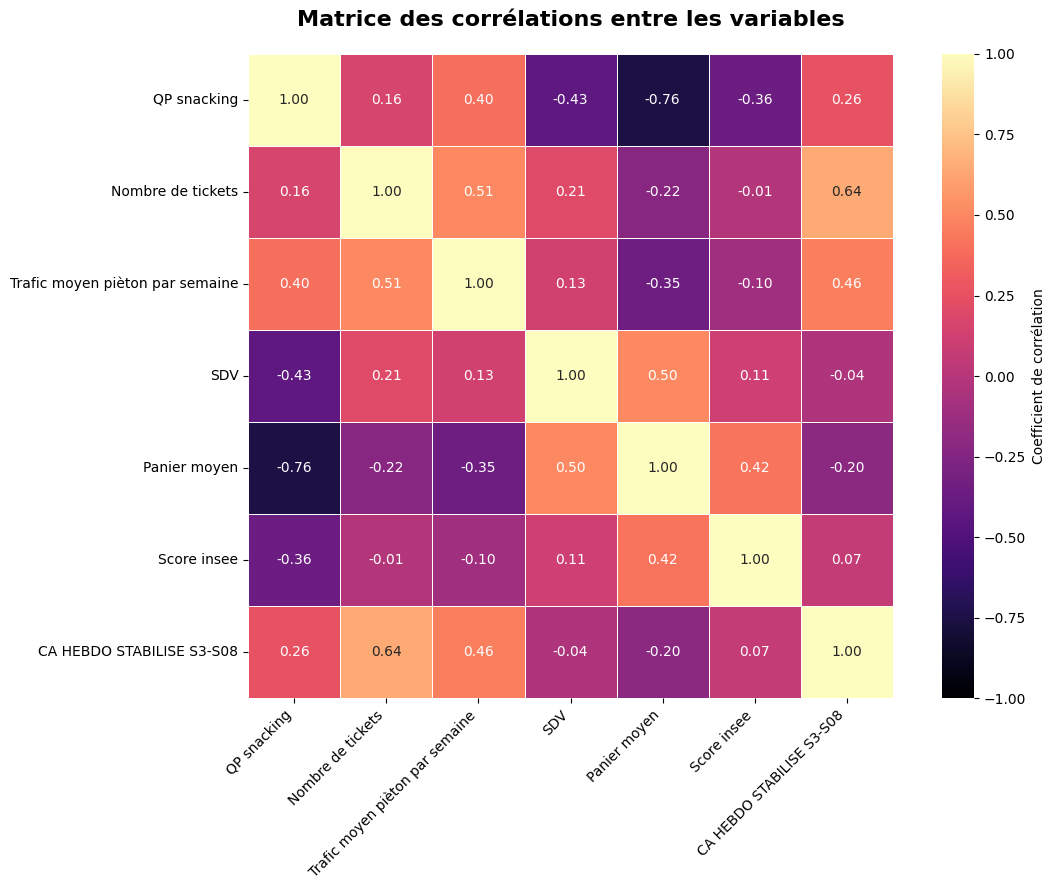

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# Sélection des variables candidates disponibles
# ============================================================

variables_candidates = [
    colonne for colonne in [
        colonne_qp,
        colonne_tickets,
        colonne_trafic,
        colonne_sdv
    ]
    if colonne is not None
]


# Ajout des variables complémentaires
for colonne in df.columns:
    nom = colonne.lower()

    est_variable_complementaire = (
        "panier" in nom
        or ("score" in nom and "insee" in nom)
        or ("ca" in nom and "magasin" in nom)
    )

    if (
        est_variable_complementaire
        and colonne not in variables_candidates
        and colonne != colonne_cible
    ):
        variables_candidates.append(colonne)


# Suppression des doublons éventuels
variables_candidates = list(
    dict.fromkeys(variables_candidates)
)


# Conversion des variables en format numérique
variables_a_analyser = variables_candidates + [
    colonne_cible
]

for colonne in variables_a_analyser:
    df[colonne] = pd.to_numeric(
        df[colonne],
        errors="coerce"
    )


# ============================================================
# Création de la matrice de corrélation
# ============================================================

# Suppression des colonnes qui n'existent pas dans la base
variables_correlation = [
    colonne
    for colonne in variables_a_analyser
    if colonne in df.columns
]

# Création d'une base uniquement avec les variables sélectionnées
df_correlation = df[
    variables_correlation
].copy()

# Calcul de la matrice de corrélation
matrice_correlation = (
    df_correlation
    .corr()
)


# Affichage de la matrice sous forme de tableau
print("Matrice de corrélation :")
print(matrice_correlation.round(2))


# ============================================================
# Affichage de la heatmap
# ============================================================

plt.figure(
    figsize=(12, 9)
)

sns.heatmap(
    matrice_correlation,
    annot=True,
    fmt=".2f",
    cmap="magma",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Coefficient de corrélation"
    }
)

plt.title(
    "Matrice des corrélations entre les variables",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()
plt.show()

In [7]:
# VIF sur les variables quantitatives candidates
if statsmodels_disponible:
    variables_vif = [
        colonne for colonne in variables_candidates
        if colonne != colonne_cible
    ]
    X_vif = df[variables_vif].dropna().astype(float)

    if len(X_vif) > len(variables_vif) + 1:
        X_vif_constante = sm.add_constant(X_vif)
        vif_data = pd.DataFrame({
            "Variable": X_vif_constante.columns,
            "VIF": [
                variance_inflation_factor(
                    X_vif_constante.values,
                    i
                )
                for i in range(X_vif_constante.shape[1])
            ]
        })
        print(vif_data)
    else:
        print("Pas assez de lignes complètes pour calculer le VIF.")
else:
    print("statsmodels n'est pas installé : VIF non calculé.")

                          Variable         VIF
0                            const  102.058685
1                      QP snacking    2.563033
2                Nombre de tickets    1.499468
3  Trafic moyen pièton par semaine    1.615969
4                              SDV    1.698046
5                     Panier moyen    3.080745
6                      Score insee    1.280077


## Comparaison des modèles

Les modèles sont comparés avec les mêmes indicateurs : MAE, RMSE et R². La validation Leave-One-Out est utilisée car la base est petite. Le modèle retenu doit présenter une bonne performance hors échantillon et rester interprétable.

In [8]:
def evaluer_loo(X, y):
    """Évalue un modèle de régression en Leave-One-Out."""
    modele = LinearRegression()
    validation = LeaveOneOut()
    predictions = cross_val_predict(
        modele,
        X,
        y,
        cv=validation
    )

    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))
    r2 = r2_score(y, predictions)

    return mae, rmse, r2

modeles_a_tester = {
    "QP snacking seul": [colonne_qp],
    "Nombre de tickets seul": [colonne_tickets],
    "Trafic seul": [colonne_trafic],
    "QP + tickets": [colonne_qp, colonne_tickets],
    "Tickets + trafic": [colonne_tickets, colonne_trafic],
    "QP + tickets + trafic": [colonne_qp, colonne_tickets, colonne_trafic]
}

resultats_modeles = []

for nom_modele, variables in modeles_a_tester.items():
    variables = [variable for variable in variables if variable is not None]

    if not variables:
        continue

    sous_base = df[variables + [colonne_cible]].dropna().copy()
    sous_base = sous_base[sous_base[colonne_cible] > 0]

    if len(sous_base) < 4:
        continue

    X_test_modele = sous_base[variables]
    y_test_modele = sous_base[colonne_cible]

    mae, rmse, r2 = evaluer_loo(
        X_test_modele,
        y_test_modele
    )

    resultats_modeles.append({
        "Modèle": nom_modele,
        "Variables": ", ".join(variables),
        "Nombre de magasins": len(sous_base),
        "MAE LOO (€)": mae,
        "RMSE LOO (€)": rmse,
        "R² LOO": r2
    })

tableau_comparatif = (
    pd.DataFrame(resultats_modeles)
    .sort_values(by="MAE LOO (€)")
    .reset_index(drop=True)
)

print(tableau_comparatif.round(3))

                   Modèle                                          Variables  \
0  Nombre de tickets seul                                  Nombre de tickets   
1             Trafic seul                    Trafic moyen pièton par semaine   
2            QP + tickets                     QP snacking, Nombre de tickets   
3        Tickets + trafic  Nombre de tickets, Trafic moyen pièton par sem...   
4   QP + tickets + trafic  QP snacking, Nombre de tickets, Trafic moyen p...   
5        QP snacking seul                                        QP snacking   

   Nombre de magasins  MAE LOO (€)  RMSE LOO (€)  R² LOO  
0                  22      422.526       541.236   0.255  
1                  22      430.788       624.602   0.008  
2                  22      435.471       551.856   0.226  
3                  22      451.207       594.450   0.102  
4                  22      462.830       604.747   0.070  
5                  22      472.447       666.121  -0.128  


## Choix du modèle final

Dans le cadre du POC, la régression linéaire simple avec le nombre de tickets est retenue. La sélection repose sur les résultats Leave-One-Out, la simplicité du modèle et son interprétabilité métier.

In [9]:
# Base finale du modèle simple
df_model = df[[colonne_tickets, colonne_cible]].dropna().copy()
df_model = df_model[
    (df_model[colonne_tickets] > 0) &
    (df_model[colonne_cible] > 0)
].copy()

# Variables finales
X_final = df_model[[colonne_tickets]]
y_final = df_model[colonne_cible]

# Alias conservés pour correspondre à ton ancien notebook
# X_2 et y_2 représentent le modèle « Nombre de tickets seul ».
X_2 = X_final.copy()
y_2 = y_final.copy()

# Entraînement sur l'ensemble des magasins exploitables
modele_final = LinearRegression()
modele_final.fit(X_2, y_2)

# Équation
constante = modele_final.intercept_
coefficient_tickets = modele_final.coef_[0]

print(f"Nombre de magasins utilisés : {len(df_model)}")
print(f"Constante : {constante:.2f} €")
print(f"Coefficient : {coefficient_tickets:.4f}")
print(
    f"Équation : CA stabilisé prédit = "
    f"{constante:.2f} + "
    f"{coefficient_tickets:.4f} × Nombre de tickets"
)

Nombre de magasins utilisés : 22
Constante : -250.06 €
Coefficient : 0.8920
Équation : CA stabilisé prédit = -250.06 + 0.8920 × Nombre de tickets


In [10]:
# Validation Leave-One-Out du modèle final
predictions_loo = cross_val_predict(
    LinearRegression(),
    X_final,
    y_final,
    cv=LeaveOneOut()
)

mae_loo_final = mean_absolute_error(y_final, predictions_loo)
rmse_loo_final = np.sqrt(mean_squared_error(y_final, predictions_loo))
r2_loo_final = r2_score(y_final, predictions_loo)

print(f"MAE LOO : {mae_loo_final:.2f} €")
print(f"RMSE LOO : {rmse_loo_final:.2f} €")
print(f"R² LOO : {r2_loo_final:.3f}")

MAE LOO : 422.53 €
RMSE LOO : 541.24 €
R² LOO : 0.255


In [11]:
# Analyse des erreurs sur les magasins historiques
resultats_erreurs = df_model.copy()
resultats_erreurs["CA prédit"] = modele_final.predict(X_final)
resultats_erreurs["Erreur"] = (
    resultats_erreurs[colonne_cible] - resultats_erreurs["CA prédit"]
)
resultats_erreurs["Erreur absolue"] = resultats_erreurs["Erreur"].abs()

resultats_erreurs.sort_values(
    by="Erreur absolue",
    ascending=False
).head(10)

,Nombre de tickets,CA HEBDO STABILISE S3-S08,CA prédit,Erreur,Erreur absolue
15,2041.428571,2802.437333,1570.917148,1231.520185,1231.520185
1,1520.857143,1936.184333,1106.561890,829.622444,829.622444
8,1782.214286,632.847833,1339.695245,-706.847412,706.847412
16,2100.023810,1021.200000,1623.184725,-601.984725,601.984725
14,1265.357143,1430.827500,878.653169,552.174331,552.174331
9,1668.821429,726.038000,1238.547609,-512.509609,512.509609
18,1669.357143,727.511333,1239.025471,-511.514138,511.514138
19,1262.416667,378.299667,876.030233,-497.730566,497.730566
0,975.178571,1085.298333,619.810792,465.487542,465.487542
20,2331.869048,2292.225000,1829.993147,462.231853,462.231853


## Scoring métier

La prédiction en euros est transformée en niveau de priorité.

- CA prédit supérieur ou égal à 850 € : Priorité 1
- CA prédit entre 700 € et 850 € : Priorité 2
- CA prédit inférieur à 700 € : Non prioritaire

In [12]:
def attribuer_priorite(ca_predit):
    if ca_predit >= 850:
        return "Priorité 1"
    elif ca_predit >= 700:
        return "Priorité 2"
    else:
        return "Non prioritaire"

# Scoring des magasins historiques
df_scoring_historique = df_model.copy()
df_scoring_historique["CA prédit"] = modele_final.predict(X_final)
df_scoring_historique["Score / 850"] = (
    df_scoring_historique["CA prédit"] / 850 * 100
)
df_scoring_historique["Priorité"] = (
    df_scoring_historique["CA prédit"].apply(attribuer_priorite)
)

print(df_scoring_historique.sort_values(
    by="CA prédit",
    ascending=False
).head(10))

    Nombre de tickets  CA HEBDO STABILISE S3-S08    CA prédit  Score / 850  \
20        2331.869048                2292.225000  1829.993147   215.293311   
16        2100.023810                1021.200000  1623.184725   190.962909   
15        2041.428571                2802.437333  1570.917148   184.813782   
8         1782.214286                 632.847833  1339.695245   157.611205   
11        1774.535714                1086.501000  1332.845877   156.805397   
18        1669.357143                 727.511333  1239.025471   145.767703   
9         1668.821429                 726.038000  1238.547609   145.711483   
1         1520.857143                1936.184333  1106.561890   130.183752   
7         1470.560976                1064.304333  1061.697173   124.905550   
13        1412.345238                 963.450167  1009.768115   118.796249   

      Priorité  
20  Priorité 1  
16  Priorité 1  
15  Priorité 1  
8   Priorité 1  
11  Priorité 1  
18  Priorité 1  
9   Priorité 1  
1   P

In [13]:
# Fonction de scoring des magasins candidats
def predire_magasins(fichier_excel, exporter=True):
    """
    Prédit le CA potentiel de magasins sans corner.

    Le fichier candidat doit contenir au minimum :
    - Nombre de tickets
    Une colonne Nom et une colonne SDV sont recommandées pour le suivi terrain.
    """
    df_futurs = pd.read_excel(fichier_excel)
    df_futurs.columns = (
        df_futurs.columns
        .astype(str)
        .str.replace("\n", " ", regex=False)
        .str.replace("\xa0", " ", regex=False)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    if colonne_tickets not in df_futurs.columns:
        raise KeyError(
            f"La colonne '{colonne_tickets}' est absente du fichier candidat."
        )

    df_futurs[colonne_tickets] = pd.to_numeric(
        df_futurs[colonne_tickets],
        errors="coerce"
    )

    lignes_invalides = df_futurs[colonne_tickets].isna().sum()
    if lignes_invalides > 0:
        print(f"Lignes exclues car nombre de tickets manquant : {lignes_invalides}")

    df_futurs = df_futurs.dropna(
        subset=[colonne_tickets]
    ).copy()
    df_futurs = df_futurs[df_futurs[colonne_tickets] > 0].copy()

    df_futurs["CA prédit"] = modele_final.predict(
        df_futurs[[colonne_tickets]]
    )
    df_futurs["Score / 850"] = df_futurs["CA prédit"] / 850 * 100
    df_futurs["Priorité"] = df_futurs["CA prédit"].apply(attribuer_priorite)

    if colonne_sdv is not None and colonne_sdv in df_futurs.columns:
        df_futurs["Faisabilité opérationnelle"] = np.where(
            df_futurs[colonne_sdv].notna(),
            "À vérifier sur le terrain",
            "SDV manquante"
        )
    else:
        df_futurs["Faisabilité opérationnelle"] = "À vérifier sur le terrain"

    colonnes_sortie = [
        colonne for colonne in [
            "Nom",
            colonne_tickets,
            "CA prédit",
            "Score / 850",
            "Priorité",
            colonne_sdv,
            "Faisabilité opérationnelle"
        ]
        if colonne is not None and colonne in df_futurs.columns
    ]

    tableau_final = df_futurs[colonnes_sortie].sort_values(
        by="CA prédit",
        ascending=False
    )

    if exporter:
        tableau_final.to_excel(
            "resultats_scoring_magasins.xlsx",
            index=False
        )
        print("Export créé : resultats_scoring_magasins.xlsx")

    return tableau_final

In [14]:
resultats = predire_magasins(
    "Petites armoires.xlsx",
    exporter=True
)

resultats

Lignes exclues car nombre de tickets manquant : 2
Export créé : resultats_scoring_magasins.xlsx


,Nom,Nombre de tickets,CA prédit,Score / 850,Priorité,Faisabilité opérationnelle
2,BREDIS,2048.963855,1577.638702,185.604553,Priorité 1,À vérifier sur le terrain
4,HONODIS,2030.678571,1561.328033,183.685651,Priorité 1,À vérifier sur le terrain
8,MK ALMA,1780.904762,1338.527136,157.473781,Priorité 1,À vérifier sur le terrain
26,BERCY DISTRIBUTION,1767.035714,1326.155797,156.018329,Priorité 1,À vérifier sur le terrain
5,NEW BOURDONNAIS,1633.445783,1206.992156,141.999077,Priorité 1,À vérifier sur le terrain
33,MK MARBEUF,1509.595238,1096.516151,129.001900,Priorité 1,À vérifier sur le terrain
6,MK BOETIE,1495.273810,1083.741284,127.498975,Priorité 1,À vérifier sur le terrain
16,TED,1494.809524,1083.327136,127.450251,Priorité 1,À vérifier sur le terrain
23,MK MURAT,1451.940476,1045.087489,122.951469,Priorité 1,À vérifier sur le terrain
7,MARGOTTE,1382.903614,983.505873,115.706573,Priorité 1,À vérifier sur le terrain


## Conclusion du notebook

Le modèle final est une régression linéaire simple avec le nombre de tickets. Il produit une estimation du CA moyen stabilisé. Cette estimation est ensuite comparée aux seuils de 850 € et 700 €, puis complétée par une vérification de la faisabilité opérationnelle.

Le modèle doit être considéré comme un outil d’aide à la décision. Après les premiers déploiements du nouveau modèle d’armoire, les CA réels devront être ajoutés à la base afin d’évaluer et de réentraîner le modèle.